<a href="https://colab.research.google.com/github/vanthuannguyen8000-maker/code-scanning-demo/blob/main/Copy_of_AI_CTO_Language_Models_Transformers_concise_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-CTO: From Text to Language Models

This notebook is meant to be **walked through**, not used as a coding lab.

We keep one running corpus — **Tiny Shakespeare** — and repeatedly ask the same question:

> Given some context, what token should come next?

Progression:

**text → tokens → n-grams → embeddings → RNN → LSTM**

Then, after the in-class stopping point:

**the same next-token task → Transformer**

## 1. Text → tokens

A language model assigns probabilities to token sequences:

$$
p(w_1,\ldots,w_T)=\prod_{t=1}^{T}p(w_t\mid w_1,\ldots,w_{t-1}).
$$

So language modeling becomes a supervised prediction problem:

**previous tokens → next token**

In [ ]:
# Load the one corpus used throughout the notebook.
import re, time, random, gzip, urllib.request
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(url).read().decode("utf-8")
tokens = re.findall(r"[a-z']+|[.,!?;:]", text.lower())
print(f"{len(text):,} characters, {len(tokens):,} word tokens")
print(tokens[:30])

1,115,394 characters, 250,371 word tokens
['first', 'citizen', ':', 'before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', 'all', ':', 'speak', ',', 'speak', '.', 'first', 'citizen', ':', 'you', 'are', 'all', 'resolved', 'rather', 'to', 'die', 'than']


## 2. A simple n-gram language model

An n-gram model predicts the next word from the previous $n-1$ words.

It learns by **counting**:

$$
p(w_t\mid c)\approx \frac{\text{count}(c,w_t)}{\text{count}(c,\cdot)}.
$$

We also keep shorter contexts so the model can **back off** when a prompt is unseen.

In [ ]:
# Count next-word frequencies for contexts up to length n-1.
def fit_ngram(words, n):
    tables = {k: defaultdict(Counter) for k in range(1, n)}
    for i in range(1, len(words)):
        for k in range(1, min(n, i + 1)):
            context = tuple(words[i-k:i])
            tables[k][context][words[i]] += 1
    return tables

In [ ]:
# Sample one next word at a time; back off if a context is unseen.
def generate(model, prompt, steps=25):
    out = prompt.lower().split()
    for _ in range(steps):
        choices = None
        for k in sorted(model, reverse=True):
            context = tuple(out[-k:])
            if context in model[k]:
                choices = model[k][context]
                break
        if choices is None:
            break
        words, counts = zip(*choices.items())
        out.append(random.choices(words, weights=counts)[0])
    return " ".join(out)

### More context usually makes the text more coherent — and more repeatable

For each context length, we generate **twice from the exact same prompt**.

With short context, many continuations remain plausible, so the two samples can diverge quickly.
With longer context, the next-word distribution is often narrower, so repeated generations tend to look more similar.

The prompt contains an unseen word — **Amir** — so the model must initially back off to a suffix it recognizes.

In [ ]:
# Generate twice from the same prompt to expose how constrained the model is.
sample = tokens[:80_000]

for n in [2, 3, 5]:
    model = fit_ngram(sample, n)
    print(f"\ncontext = {n-1} word(s)")
    print(generate(model, "amir went to", steps=18))
    print(generate(model, "amir went to", steps=18))


context = 1 word(s)
amir went to obey , if he turns ! hoo ! lo , dear blood ! pale , as i have
amir went to france ; like toys as for conscience flies . volumnia : the remove it again , poor bolingbroke

context = 2 word(s)
amir went to france , his son george fall into the fatal bowels of ungrateful rome , coriolanus ; never man
amir went to france to fetch his queen : to my love alike and none less dear than thine and my

context = 4 word(s)
amir went to france to fetch his queen : now swallow down that lie . for gloucester's death , i slew
amir went to france to fetch his queen : now swallow down that lie . for gloucester's death , i slew


### But increasing context is not free

For a dictionary-based n-gram model, **generation itself need not become dramatically slower** as $n$ increases.

The real problems are:

- more distinct contexts to store;
- more work to build the model;
- rapidly increasing **data sparsity** — most long contexts are seen only once.

That is the scaling failure worth visualizing.

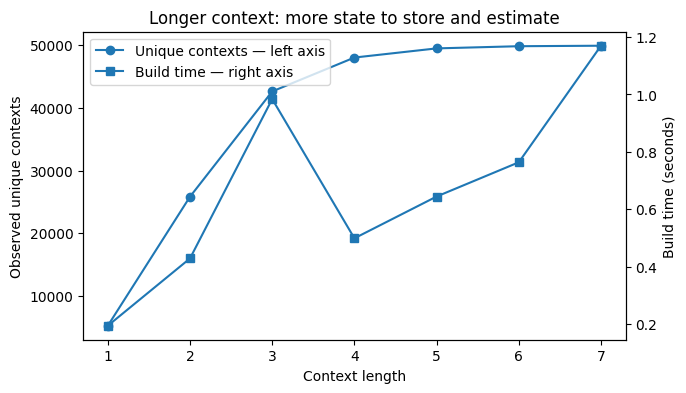

Singleton contexts (%): {np.int64(1): np.float64(54.9), np.int64(2): np.float64(79.1), np.int64(3): np.float64(92.6), np.int64(4): np.float64(97.5), np.int64(5): np.float64(99.2), np.int64(6): np.float64(99.7), np.int64(7): np.float64(99.9)}


In [ ]:
# Measure model size and fitting cost as the context grows.
stats = []
for n in range(2, 9):
    t0 = time.perf_counter()
    m = fit_ngram(tokens[:50_000], n)
    counts = np.array([sum(c.values()) for c in m[n-1].values()])
    stats.append((n-1, len(counts), 100*np.mean(counts == 1), time.perf_counter()-t0))

ctx, unique, singleton, seconds = map(np.array, zip(*stats))
fig, ax = plt.subplots(figsize=(7, 4))
a, = ax.plot(ctx, unique, marker="o", label="Unique contexts — left axis")
ax.set(xlabel="Context length", ylabel="Observed unique contexts")
ax2 = ax.twinx()
b, = ax2.plot(ctx, seconds, marker="s", label="Build time — right axis")
ax2.set_ylabel("Build time (seconds)")
ax.legend(handles=[a, b], loc="upper left")
plt.title("Longer context: more state to store and estimate")
plt.show()
print("Singleton contexts (%):", dict(zip(ctx, singleton.round(1))))

## 3. Word embeddings: words become geometry

Count models treat word identities as unrelated symbols.

Embeddings instead map each word to a dense vector:

$$
w \mapsto e_w\in\mathbb{R}^d.
$$

We use pretrained **GloVe** vectors here so the geometry is visible immediately.

In [ ]:
glove = Path("glove-wiki-gigaword-50.gz")
if not glove.exists():
    url = ("https://github.com/RaRe-Technologies/gensim-data/releases/download/"
           "glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz")
    urllib.request.urlretrieve(url, glove)

words, vectors = [], []
with gzip.open(glove, "rt", encoding="utf-8") as f:
    vocab_size, dim = map(int, f.readline().split())
    for i, line in enumerate(f):
        if i == 100_000: break
        word, *values = line.split()
        words.append(word); vectors.append(values)
E = np.asarray(vectors, dtype=np.float32)
idx = {w: i for i, w in enumerate(words)}
print(E.shape)

(100000, 50)


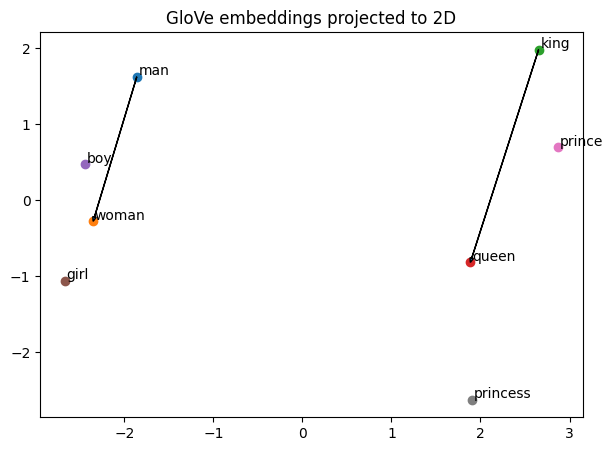

In [ ]:
show = ["man", "woman", "king", "queen", "boy", "girl", "prince", "princess"]
X = E[[idx[w] for w in show]]
X = X - X.mean(0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)
Z = X @ Vt[:2].T

plt.figure(figsize=(7, 5))
for word, (x, y) in zip(show, Z):
    plt.scatter(x, y); plt.text(x+.02, y+.02, word)
for a, b in [("man","woman"), ("king","queen")]:
    i, j = show.index(a), show.index(b)
    plt.arrow(*Z[i], *(Z[j]-Z[i]), length_includes_head=True, head_width=.04)
plt.title("GloVe embeddings projected to 2D")
plt.show()

### Classic embedding analogy

Now use the geometry directly:

$$
e_{\mathrm{king}} - e_{\mathrm{man}} + e_{\mathrm{woman}} \approx \; ?
$$

In [ ]:
# Exclude the three input words before taking the nearest vector.
target = E[idx["king"]] - E[idx["man"]] + E[idx["woman"]]
sim = E @ target / (np.linalg.norm(E, axis=1) * np.linalg.norm(target))
for w in ["king", "man", "woman"]:
    sim[idx[w]] = -np.inf
print("king - man + woman →", words[int(np.argmax(sim))])

king - man + woman → queen


### Audience prediction

We just saw that **man → woman** is approximately the same relationship as **king → queen**.

Before running the next cell, ask:

> If **woman → princess**, then **man → ?**

$$
e_{\mathrm{princess}} - e_{\mathrm{woman}} + e_{\mathrm{man}} \approx \; ?
$$

In [ ]:
# Reveal the audience prediction.
target = E[idx["princess"]] - E[idx["woman"]] + E[idx["man"]]
sim = E @ target / (np.linalg.norm(E, axis=1) * np.linalg.norm(target))
for w in ["princess", "woman", "man"]:
    sim[idx[w]] = -np.inf

top = np.argsort(sim)[-5:][::-1]
print("princess - woman + man →")
for j in top:
    print(f"  {words[j]:12s} cosine={sim[j]:.3f}")

princess - woman + man →
  prince       cosine=0.828
  queen        cosine=0.803
  king         cosine=0.729
  empress      cosine=0.691
  crown        cosine=0.688


## 4. The same corpus with off-the-shelf recurrent units

Now we stop manually designing a language model.

PyTorch already gives us sequence-processing building blocks:

- `nn.RNN`
- `nn.LSTM`

Both read a sequence and repeatedly update an internal state.

To make training quick enough to watch, we use **characters as tokens**.  
It is still the same Shakespeare corpus and the same next-token prediction task.

In [ ]:
# Same Shakespeare corpus, now using characters as tokens.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
chars = sorted(set(text))
stoi = {c:i for i,c in enumerate(chars)}
itos = {i:c for c,i in stoi.items()}
data = torch.tensor([stoi[c] for c in text[:300_000]])
cut = int(.9 * len(data))
train_data, val_data = data[:cut], data[cut:]
SEQ, BATCH = 80, 64

def batch(split):
    d = train_data if split == "train" else val_data
    s = torch.randint(len(d)-SEQ-1, (BATCH,))
    x = torch.stack([d[i:i+SEQ] for i in s])
    y = torch.stack([d[i+1:i+SEQ+1] for i in s])
    return x.to(device), y.to(device)

In [ ]:
# Same language-model head; only the recurrent unit changes.
class RecurrentLM(nn.Module):
    def __init__(self, kind, vocab, emb=64, hidden=128):
        super().__init__()
        self.embed = nn.Embedding(vocab, emb)
        unit = nn.RNN if kind == "RNN" else nn.LSTM
        self.core = unit(emb, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab)

    def forward(self, x):
        h, _ = self.core(self.embed(x))
        return self.head(h)

rnn = RecurrentLM("RNN", len(chars)).to(device)
lstm = RecurrentLM("LSTM", len(chars)).to(device)

In [ ]:
from IPython.display import clear_output

def train_step(model, opt):
    # One minibatch update.
    x, y = batch("train")
    loss = F.cross_entropy(model(x).reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def validation_loss(model):
    # Evaluate on a fresh validation batch.
    x, y = batch("val")
    return float(F.cross_entropy(model(x).reshape(-1, len(chars)), y.reshape(-1)))

### Train RNN and LSTM side by side

The LSTM does more work per step because it has gates and an explicit memory cell.

Its intended advantage is **retaining useful information over longer sequences**.

Whether that advantage is already visible in this tiny experiment is empirical — run both and compare.

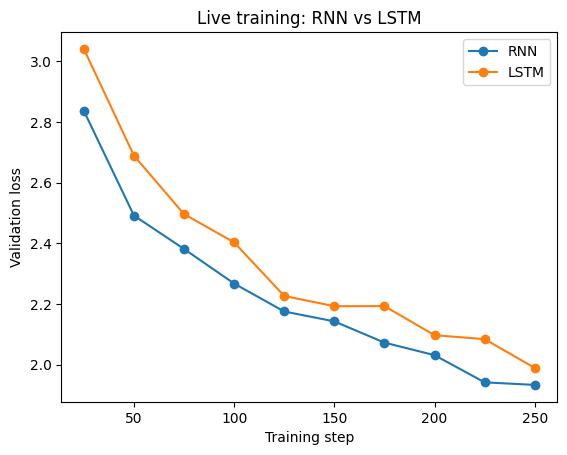

{'RNN': '10.9s', 'LSTM': '31.2s'}


In [ ]:
# Train both models together so their loss curves update side by side.
models = {"RNN": rnn, "LSTM": lstm}
opts = {n: torch.optim.AdamW(m.parameters(), lr=2e-3) for n, m in models.items()}
history = {n: [] for n in models}
elapsed = {n: 0.0 for n in models}
for step in range(1, 251):
    for name, model in models.items():
        t0 = time.perf_counter(); train_step(model, opts[name])
        elapsed[name] += time.perf_counter() - t0
    if step % 25 == 0:
        clear_output(wait=True)
        for name, model in models.items():
            history[name].append((step, validation_loss(model)))
        for name, h in history.items():
            x, y = zip(*h); plt.plot(x, y, marker="o", label=name)
        plt.xlabel("Training step"); plt.ylabel("Validation loss")
        plt.title("Live training: RNN vs LSTM"); plt.legend(); plt.show()
print({name: f"{elapsed[name]:.1f}s" for name in models})
results = history

In [ ]:
@torch.no_grad()
def sample_model(model, prompt="ROMEO:", steps=200, temperature=.8):
    ids = [stoi[c] for c in prompt]
    for _ in range(steps):
        x = torch.tensor([ids[-SEQ:]], device=device)
        logits = model(x)[0, -1] / temperature
        ids.append(int(torch.multinomial(torch.softmax(logits, 0), 1)))
    return "".join(itos[i] for i in ids)

print("RNN:\n", sample_model(rnn, steps=120))
print("\nLSTM:\n", sample_model(lstm, steps=120))

RNN:
 ROMEO:
Your conder as prope,
The come, to me tround pill inger my sogesting suptes not the with onave reblotes. Martee'd a for

LSTM:
 ROMEO:
Iuld the as to you condsad, and this the anown speantt that the ears. What I dow
On say wees hangrech thy lovese a vaie


# In-class stopping point

At this point the progression is already visible:

| Model | What represents context? | Main issue |
|---|---|---|
| n-gram | exact previous words | sparsity explodes with context |
| RNN | recurrent hidden state | long-range information can fade |
| LSTM | gated hidden + cell state | better memory, but still sequential |

The important conceptual shift is:

> We kept the **same next-token problem** and changed only the mechanism used to represent and process context.

---

# Self-study: continue the same progression to Transformers

A Transformer changes the context mechanism again.

Instead of passing information through a recurrent state one step at a time, each token can directly combine information from relevant earlier tokens using **self-attention**.

For language modeling we apply a **causal mask**, so a token cannot look into the future.

In [ ]:
# Same next-token task; self-attention replaces recurrent memory.
class TransformerLM(nn.Module):
    def __init__(self, vocab, d=96, heads=4, layers=2):
        super().__init__()
        self.embed = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(SEQ, d)
        block = nn.TransformerEncoderLayer(d, heads, 4*d, batch_first=True)
        self.core = nn.TransformerEncoder(block, layers)
        self.head = nn.Linear(d, vocab)

    def forward(self, x):
        T = x.shape[1]
        p = torch.arange(T, device=x.device)
        h = self.embed(x) + self.pos(p)[None]
        mask = torch.triu(torch.ones(T,T,device=x.device,dtype=torch.bool), 1)
        return self.head(self.core(h, mask=mask))

transformer = TransformerLM(len(chars)).to(device)

### Same corpus. Same loss. Same generator. New context mechanism.

Because the Transformer exposes the same interface — token IDs in, next-token logits out — the **same training loop** works unchanged.

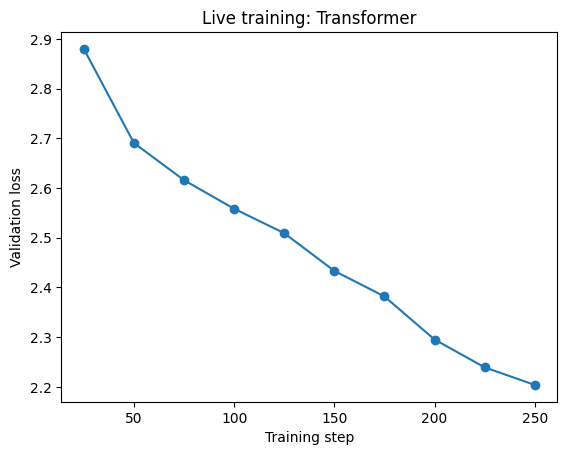

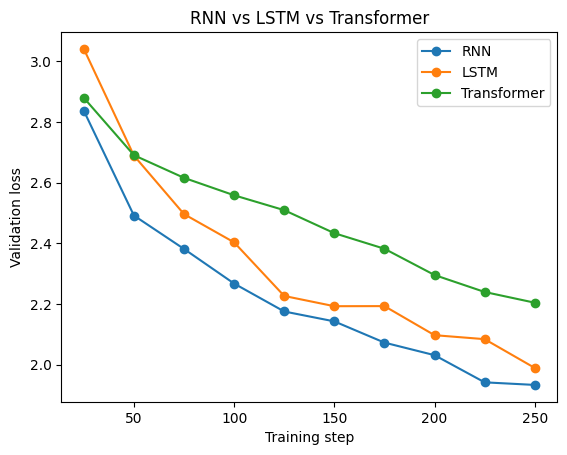

ROMEO:
Wiblerre hish his bre
Thoust ther'd th your pror in coisur.

Prind, thryou bese pou conge belfbrold litidie,
KI Lo much mang'ls benace hoseare.

Farrond I ther youe this the for C


In [ ]:
# Same training objective again; only the sequence model changes.
opt = torch.optim.AdamW(transformer.parameters(), lr=2e-3)
transformer_history = []
for step in range(1, 251):
    train_step(transformer, opt)
    if step % 25 == 0:
        transformer_history.append((step, validation_loss(transformer)))
        clear_output(wait=True)
        x, y = zip(*transformer_history)
        plt.plot(x, y, marker="o")
        plt.xlabel("Training step"); plt.ylabel("Validation loss")
        plt.title("Live training: Transformer"); plt.show()

results["Transformer"] = transformer_history
for name, h in results.items():
    x, y = zip(*h); plt.plot(x, y, marker="o", label=name)
plt.xlabel("Training step"); plt.ylabel("Validation loss")
plt.title("RNN vs LSTM vs Transformer"); plt.legend(); plt.show()
print(sample_model(transformer, steps=180))

## Final picture

We never changed the fundamental task:

$$
\text{context} \longrightarrow p(\text{next token}).
$$

We changed how context is represented:

**exact words → recurrent state → gated memory → attention over tokens**

That progression is the conceptual bridge from classical language models to modern LLMs.